# 🎓 Student Performance Prediction — Phase 3: Preprocessing
AIML Mini Project — UCI Student Dataset (Math)

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data (comma-separated; semicolon fallback just in case)
try:
    df = pd.read_csv('../data/student_data.csv')
    print("Loaded with comma separator")
except:
    df = pd.read_csv('../data/student_data.csv', sep=';')
    print("Loaded with semicolon separator")

print("\nSHAPE:", df.shape)
df.head()


Loaded with comma separator

SHAPE: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 1️⃣ Create the target: G3 (0–20) → Letter grade (A–F)

Grade distribution:
grade
A     40
B     60
C     62
D    103
F    130
Name: count, dtype: int64


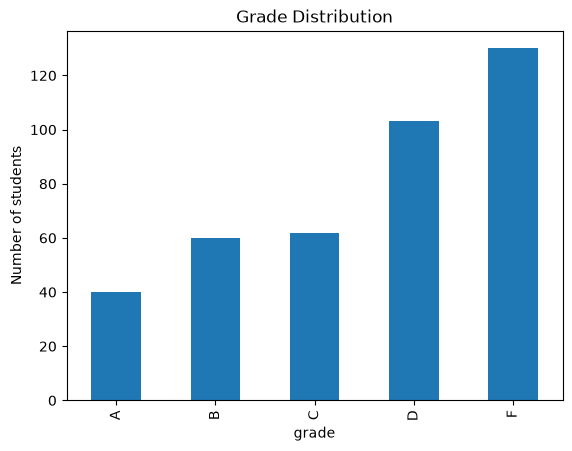

In [10]:
def score_to_grade(g):
    if g >= 16:
        return 'A'
    elif g >= 14:
        return 'B'
    elif g >= 12:
        return 'C'
    elif g >= 10:
        return 'D'
    else:
        return 'F'

df['grade'] = df['G3'].apply(score_to_grade)

print("Grade distribution:")
print(df['grade'].value_counts().sort_index())

df['grade'].value_counts().sort_index().plot(kind='bar', title='Grade Distribution')
plt.ylabel('Number of students')
plt.show()


## 2️⃣ Health checks (missing values + duplicates)

In [11]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Missing values: 0
Duplicate rows: 0


## 3️⃣ Drop leaky columns
**Design decision:** G1 and G2 are past grades. Keeping them would make prediction trivially easy but USELESS for *early* warning — the project's whole purpose. We predict using only early-knowable info.

In [12]:
# Work on a copy so raw df stays untouched (good habit!)
df_model = df.drop(columns=['G1', 'G2', 'G3'])

print("Model-ready shape:", df_model.shape)
df_model.head(3)


Model-ready shape: (395, 31)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,grade
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,6,F
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,4,F
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,10,D


## 4️⃣ Encode categoricals (one-hot) + separate X and y

In [13]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=['grade'])   # features
y = df_model['grade']                  # target

# One-hot encode nominal categoricals (yes/no become 0/1 automatically)
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoded shape:", X.shape)
X.head(3)


Encoded shape: (395, 39)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0


## 5️⃣ Train/Test split — stratified!
`stratify=y` keeps grade proportions identical in train and test (critical because classes are imbalanced).

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nTrain grade balance:")
print(y_train.value_counts().sort_index())


Train: (316, 39) | Test: (79, 39)

Train grade balance:
grade
A     32
B     48
C     50
D     82
F    104
Name: count, dtype: int64
